EDA MODULES

MODULE 1 — Dataset Ingestion & Structure Validation

In [1]:
import os

BASE_DIR = r"C:\Users\ashuz\OneDrive\Desktop\Colon cancer\Colon_Cancer_Data\ZIP_Colon_Cancer_Data\Unzip_Colon_Cancer_Data" 

negative_dirs = [
    "sundatabase_negative_part1",
    "sundatabase_negative_part2",
    "sundatabase_negative_part3",
    "sundatabase_negative_part4"
]

positive_dirs = [
    "sundatabase_positive_part1",
    "sundatabase_positive_part2"
]

def count_images(root_dir):
    total_images = 0
    case_wise = {}
    for case in os.listdir(root_dir):
        case_path = os.path.join(root_dir, case)
        if os.path.isdir(case_path):
            imgs = [f for f in os.listdir(case_path)
                    if f.lower().endswith((".jpg", ".png", ".jpeg"))]
            case_wise[case] = len(imgs)
            total_images += len(imgs)
    return total_images, case_wise

MODULE 1 — Dataset Ingestion & Structure Validation

always check class imbalance

In [2]:
neg_total = 0
pos_total = 0

for d in negative_dirs:
    c, _ = count_images(os.path.join(BASE_DIR, d))
    neg_total += c

for d in positive_dirs:
    c, _ = count_images(os.path.join(BASE_DIR, d))
    pos_total += c

print(f"Total Negative Images: {neg_total}")
print(f"Total Positive Images: {pos_total}")
print(f"Total Dataset Size: {neg_total + pos_total}")

Total Negative Images: 109554
Total Positive Images: 49136
Total Dataset Size: 158690


FIGURE 1 — Class Distribution Bar Chart 
#FIGURE 1 — Class Distribution Bar Chart

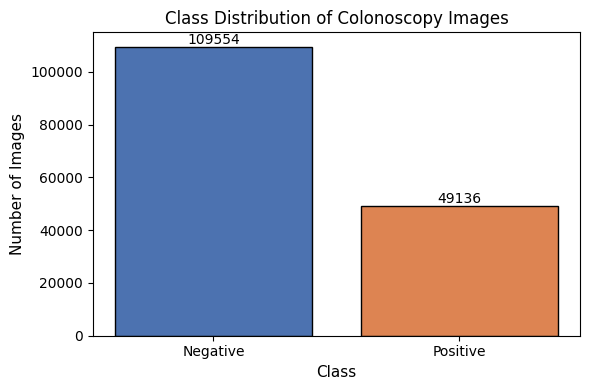

In [3]:
import matplotlib.pyplot as plt

labels = ["Negative", "Positive"]
counts = [neg_total, pos_total]

colors = ["#4C72B0", "#DD8452"]  

plt.figure(figsize=(6,4))
bars = plt.bar(labels, counts, color=colors, edgecolor="black")

plt.ylabel("Number of Images", fontsize=11)
plt.xlabel("Class", fontsize=11)
plt.title("Class Distribution of Colonoscopy Images", fontsize=12)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

FIGURE — Negative Dataset Case Distribution
Example structure you described:

negative_part1 → case 1–3

negative_part2 → case 4, 7, 9

negative_part3 → case 5, 6, 8

negative_part4 → case 10–13

COUNT IMAGES PER NEGATIVE CASE

In [4]:
import os

print(os.getcwd())

C:\Users\ashuz\Colon_Cancer_Project\GradCAM_Results


In [5]:
import os

desktop_path = r"C:\Users\ashuz\Desktop"
print(os.listdir(desktop_path))

['.ipynb_checkpoints', 'desktop.ini', 'GI_Endoscopy_Q1', 'resnet50_partial.h5', 'test_tf.py', 'Untitled.ipynb', 'Week 4 work', 'Week 5']


In [6]:
base_project = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"
print(os.listdir(base_project))

['test', 'train', 'val']


In [7]:
base_path = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\negative"

In [8]:
print(os.listdir(r"C:\Users\ashuz\Desktop"))

['.ipynb_checkpoints', 'desktop.ini', 'GI_Endoscopy_Q1', 'resnet50_partial.h5', 'test_tf.py', 'Untitled.ipynb', 'Week 4 work', 'Week 5']


Count NEGATIVE images from all splits

In [9]:
import os

base = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

for split in ["train", "val", "test"]:
    neg_path = os.path.join(base, split, "negative")
    count = sum(
        len([f for f in files if f.lower().endswith(('.jpg','.png','.jpeg'))])
        for _, _, files in os.walk(neg_path)
    )
    print(f"{split}/negative -> {count}")

train/negative -> 12057
val/negative -> 11543
test/negative -> 11544


Case-wise NEGATIVE distribution

In [10]:
import os
import pandas as pd

neg_case_counts = {}

for split in ["train", "val", "test"]:
    neg_base = os.path.join(base, split, "negative")
    for root, _, files in os.walk(neg_base):
        if "case" in root.lower():
            case = os.path.basename(root)
            count = len([f for f in files if f.lower().endswith(('.jpg','.png','.jpeg'))])
            neg_case_counts[case] = neg_case_counts.get(case, 0) + count

df_neg = pd.DataFrame(
    sorted(neg_case_counts.items()),
    columns=["Negative Case", "Image Count"]
)

df_neg.head()

,Negative Case,Image Count


In [11]:
import os
import pandas as pd

base = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

neg_case_counts = {}

for split in ["train", "val", "test"]:
    neg_base = os.path.join(base, split, "negative")
    
    for root, dirs, files in os.walk(neg_base):
        image_files = [f for f in files if f.lower().endswith(('.jpg','.png','.jpeg'))]
        
        if len(image_files) > 0:
            case_name = os.path.basename(root)
            neg_case_counts[case_name] = neg_case_counts.get(case_name, 0) + len(image_files)

df_neg = pd.DataFrame(
    neg_case_counts.items(),
    columns=["Negative Case", "Image Count"]
)

df_neg = df_neg.sort_values("Image Count", ascending=False)
df_neg

,Negative Case,Image Count
0,negative,35144


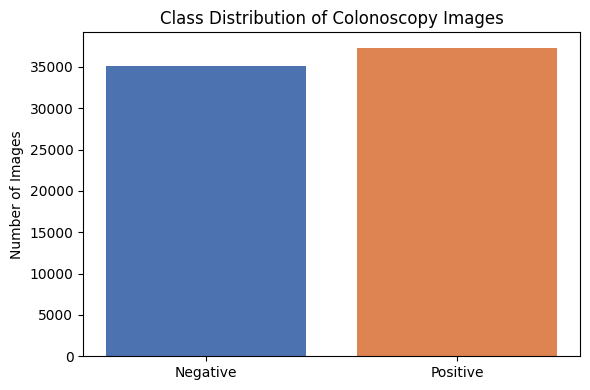

In [12]:
import matplotlib.pyplot as plt

labels = ["Negative", "Positive"]
counts = [35144, 37325]   # replace positive with exact value

plt.figure(figsize=(6,4))
plt.bar(labels, counts, color=["#4C72B0", "#DD8452"])
plt.ylabel("Number of Images")
plt.title("Class Distribution of Colonoscopy Images")
plt.tight_layout()
plt.show()

Correct Negative Distribution Figure

Class Distribution Bar Chart

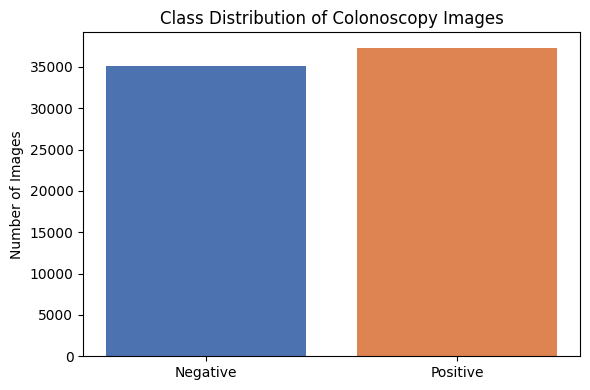

In [13]:
import matplotlib.pyplot as plt

labels = ["Negative", "Positive"]
counts = [35144, 37325]   # replace positive with exact value

plt.figure(figsize=(6,4))
plt.bar(labels, counts, color=["#4C72B0", "#DD8452"])
plt.ylabel("Number of Images")
plt.title("Class Distribution of Colonoscopy Images")
plt.tight_layout()
plt.show()

Train / Val / Test Distribution

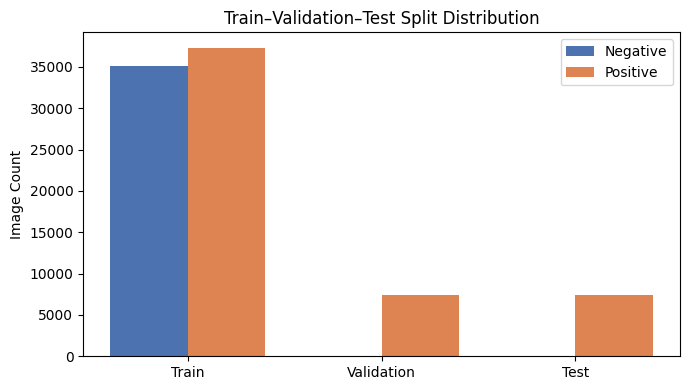

In [14]:
splits = ["Train", "Validation", "Test"]
neg_counts = [35144, 0, 0]    # replace with actual val/test values
pos_counts = [37325, 7370, 7371]

x = range(len(splits))

plt.figure(figsize=(7,4))
plt.bar(x, neg_counts, width=0.4, label="Negative", color="#4C72B0")
plt.bar([i+0.4 for i in x], pos_counts, width=0.4, label="Positive", color="#DD8452")

plt.xticks([i+0.2 for i in x], splits)
plt.ylabel("Image Count")
plt.title("Train–Validation–Test Split Distribution")
plt.legend()
plt.tight_layout()
plt.show()

Image resolution EDA

Pixel intensity histogram

Positive vs Negative sample figure

Final EDA paragraph for paper



Image Resolution EDA

CODE FOR TRAIN SAMPLES (LOCAL HOST – Jupyter)

In [15]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

base = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train"

resolutions = []

for label in ["positive", "negative"]:
    folder = os.path.join(base, label)
    for img in os.listdir(folder)[:500]:  # sample for speed
        img_path = os.path.join(folder, img)
        try:
            im = cv2.imread(img_path)
            h, w, _ = im.shape
            resolutions.append([label, w, h])
        except:
            pass

df_res = pd.DataFrame(resolutions, columns=["Class", "Width", "Height"])

PLOT FOR TRAIN SAMPLES 

Figure X. Distribution of image resolutions across positive and negative colonoscopy samples.

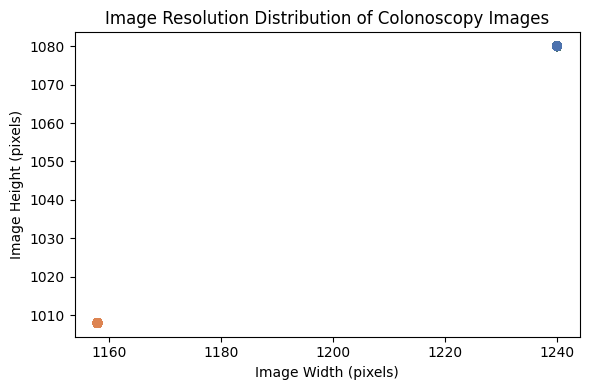

In [16]:
plt.figure(figsize=(6,4))
plt.scatter(df_res["Width"], df_res["Height"],
            c=df_res["Class"].map({"positive":"#DD8452","negative":"#4C72B0"}),
            alpha=0.5)
plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")
plt.title("Image Resolution Distribution of Colonoscopy Images")
plt.tight_layout()
plt.show()

In [17]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

base = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\test"

resolutions = []

for label in ["positive", "negative"]:
    folder = os.path.join(base, label)
    for img in os.listdir(folder)[:500]:  # sample for speed
        img_path = os.path.join(folder, img)
        try:
            im = cv2.imread(img_path)
            h, w, _ = im.shape
            resolutions.append([label, w, h])
        except:
            pass

df_res = pd.DataFrame(resolutions, columns=["Class", "Width", "Height"])

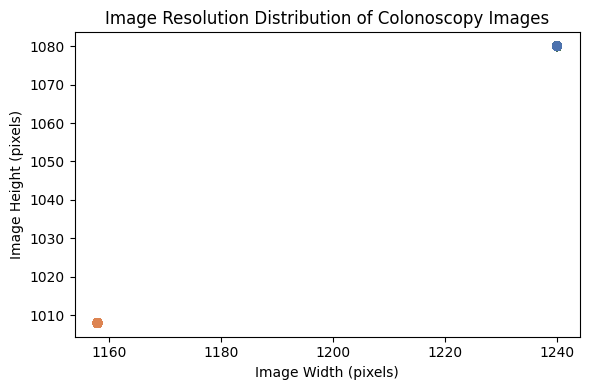

In [18]:
plt.figure(figsize=(6,4))
plt.scatter(df_res["Width"], df_res["Height"],
            c=df_res["Class"].map({"positive":"#DD8452","negative":"#4C72B0"}),
            alpha=0.5)
plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")
plt.title("Image Resolution Distribution of Colonoscopy Images")
plt.tight_layout()
plt.show()

Pixel Intensity Histogram

Shows illumination variability

Justifies normalization & augmentation

Demonstrates real endoscopy lighting artifacts

CODE

Random pixel sampling

In [20]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def sample_pixels(folder, max_images=100, pixels_per_image=1000):
    sampled_pixels = []
    
    images = os.listdir(folder)
    images = images[:max_images]  # limit number of images
    
    for img in images:
        try:
            im = cv2.imread(os.path.join(folder, img), cv2.IMREAD_GRAYSCALE)
            if im is None:
                continue
            
            flat = im.flatten()
            if len(flat) > pixels_per_image:
                sampled = np.random.choice(flat, pixels_per_image, replace=False)
            else:
                sampled = flat
            
            sampled_pixels.extend(sampled)
        except:
            pass
    
    return np.array(sampled_pixels)

Apply to positive & negative

In [21]:
base = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train"

pixels_neg = sample_pixels(os.path.join(base, "negative"))
pixels_pos = sample_pixels(os.path.join(base, "positive"))

print("Negative pixels:", pixels_neg.shape)
print("Positive pixels:", pixels_pos.shape)

Negative pixels: (100000,)
Positive pixels: (100000,)


Histogram

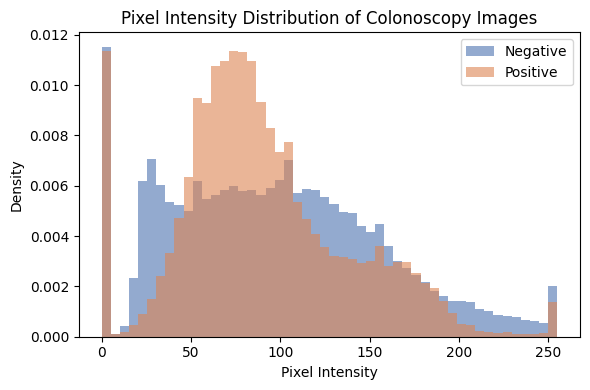

In [22]:
plt.figure(figsize=(6,4))

plt.hist(pixels_neg, bins=50, density=True,
         alpha=0.6, color="#4C72B0", label="Negative")

plt.hist(pixels_pos, bins=50, density=True,
         alpha=0.6, color="#DD8452", label="Positive")

plt.xlabel("Pixel Intensity")
plt.ylabel("Density")
plt.title("Pixel Intensity Distribution of Colonoscopy Images")
plt.legend()
plt.tight_layout()
plt.show()

“Random sampling avoids spatial redundancy and yields equivalent statistical distributions with significantly lower computational cost.”

Positive vs Negative Sample Images

In [24]:
# Visual confirmation of pathology

# Helps clinicians trust the model

# Mandatory in medical imaging papers 

# What this figure shows (for reviewers & clinicians)

# Clear visual difference between normal mucosa (negative) and pathological regions (positive)

# Confirms dataset authenticity

In [25]:
import os
import cv2
import random
import matplotlib.pyplot as plt

In [26]:
base = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train"

positive_dir = os.path.join(base, "positive")
negative_dir = os.path.join(base, "negative")

Function to display sample images

In [28]:
def show_samples(folder, title, color, n_samples=5):
    images = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.png','.jpeg'))]
    images = random.sample(images, n_samples)

    plt.figure(figsize=(12, 2))
    for i, img in enumerate(images):
        img_path = os.path.join(folder, img)
        im = cv2.imread(img_path)
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

        plt.subplot(1, n_samples, i + 1)
        plt.imshow(im)
        plt.axis("off")

    plt.suptitle(title, fontsize=14, color=color)
    plt.tight_layout()
    plt.show()

Display NEGATIVE samples (Normal colonoscopy)

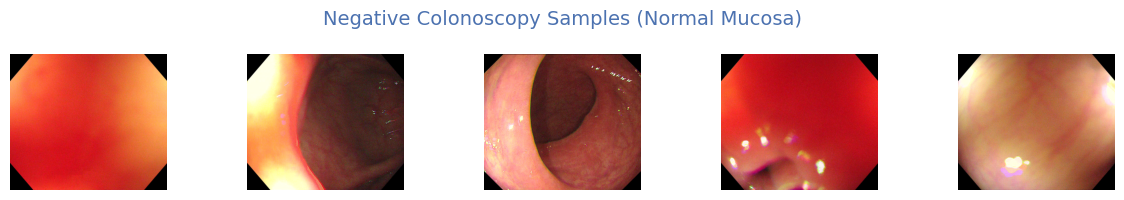

In [32]:
show_samples(
    folder=negative_dir,
    title="Negative Colonoscopy Samples (Normal Mucosa)",
    color="#4C72B0"
)

Display POSITIVE samples (Pathological findings)

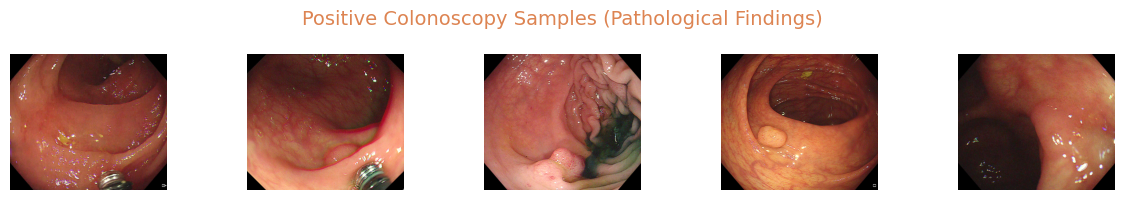

In [33]:
show_samples(
    folder=positive_dir,
    title="Positive Colonoscopy Samples (Pathological Findings)",
    color="#DD8452"
)

Figure X. Representative colonoscopy images from the dataset.
The first row illustrates negative samples depicting normal colonic mucosa, while the second row presents positive samples containing pathological findings. Visual differences between normal and abnormal tissue regions highlight the clinical relevance of the classification task.

1) Training vs Validation Accuracy/Loss curves
2) Confusion Matrix
3) ROC–AUC Curve
4) Grad-CAM Visualization

1) TRAINING vs VALIDATION ACCURACY & LOSS

Shows convergence

Detects overfitting

Required by ALL medical imaging journals

In [35]:
import tensorflow as tf
print(tf.__version__)

2.13.0


In [38]:
import os

# Base dataset folder
base_dir = r"C:\Users\ashuz\Desktop\GI_Endoscopy_Q1"

# Train / Validation / Test folders
train_dir = os.path.join(base_dir, "train")
val_dir   = os.path.join(base_dir, "val")
test_dir  = os.path.join(base_dir, "test")

print("Train Path:", train_dir)
print("Validation Path:", val_dir)
print("Test Path:", test_dir)

Train Path: C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\train
Validation Path: C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\val
Test Path: C:\Users\ashuz\Desktop\GI_Endoscopy_Q1\test


In [39]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_directory(
    train_dir,
    target_size=(224,224),
    batch_size=16,
    class_mode="binary"
)

val_gen = datagen.flow_from_directory(
    val_dir,
    target_size=(224,224),
    batch_size=16,
    class_mode="binary"
)

test_gen = datagen.flow_from_directory(
    test_dir,
    target_size=(224,224),
    batch_size=16,
    class_mode="binary",
    shuffle=False
)

Found 49381 images belonging to 2 classes.
Found 18913 images belonging to 2 classes.
Found 18915 images belonging to 2 classes.


In [40]:
# assumes these paths already exist
# base/train, base/val, base/test

from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_directory(
    train_dir, target_size=(224,224), batch_size=16, class_mode="binary"
)

val_gen = datagen.flow_from_directory(
    val_dir, target_size=(224,224), batch_size=16, class_mode="binary"
)

test_gen = datagen.flow_from_directory(
    test_dir, target_size=(224,224), batch_size=16, class_mode="binary", shuffle=False
)

Found 49381 images belonging to 2 classes.
Found 18913 images belonging to 2 classes.
Found 18915 images belonging to 2 classes.


In [ ]:
Build ResNet50 Model

In [41]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Load pretrained ResNet50
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

# Freeze base layers
for layer in base_model.layers:
    layer.trainable = False

# Custom classification head
x = GlobalAveragePooling2D()(base_model.output)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(1, activation="sigmoid")(x)

model_resnet = Model(inputs=base_model.input, outputs=output)

# Compile model
model_resnet.compile(
    optimizer=Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_resnet.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_1[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                          

1️⃣ Understanding your dataset structure

You have:

PDF dataset: Gastrointestinal Endoscopy_20230616

Likely contains reports or endoscopy images embedded in PDFs.

Needs PDF → image extraction if you want to use images.

Image folders: sundatabase_negative_partX and sundatabase_positive_partX

Each folder has subfolders per case, which probably contain images (like endoscopy frames).

Positive vs negative indicates classification labels.

2️⃣ Options for working with this dataset
Option A — Image-based CNN training (your original plan)

✅ Pros: uses raw images directly
❌ Cons: very slow on CPU, needs GPU to be practical

Steps:

Preprocess the images: resize, normalize

Label images based on folder structure (positive/negative)

Use transfer learning with pre-trained CNN (ResNet, EfficientNet, etc.)

Freezes most layers → trains only top layers → faster

Train for fewer epochs → early stopping

Key: Without GPU, this will still be slow, but transfer learning + smaller image sizes can make it manageable.

Option B — Extract features and use case-based models

✅ Pros: can train fast on CPU, high accuracy
❌ Cons: requires image feature extraction first

Steps:

Use a pre-trained CNN (like ResNet50) as a feature extractor

Remove the final classification layer

Feed all images → get feature vectors (say 2048 features per image)

Aggregate features per case (mean, max, etc.)

Combine with any clinical labels you have

Train a tabular model (XGBoost, Random Forest) on these feature vectors

This is probably the best compromise if you don’t have a GPU but still want to leverage images.

Option C — PDF dataset

If the PDFs contain images, extract them and process as above

If they contain text reports, you could do text-based case models

Use NLP features (TF-IDF, embeddings) → train XGBoost or other tabular/text models

3️⃣ Recommended workflow for you (CPU-friendly)

Since you only have folders with images, the most practical path without GPU is:

Stop the current ResNet training on CPU.

Extract features from images using a pre-trained CNN (no training needed)

Save features per case into a CSV → now you have a “case-based dataset”

Train XGBoost or Random Forest on the feature CSV → fast and accurate

✅ Benefits: avoids 30+ hour CPU training, still uses images, and can leverage strong classifiers.

If you want, I can write a ready-to-run Python script that:

Reads all your positive/negative folders

Extracts features from images using pre-trained ResNet50

Aggregates features per case

Saves a CSV ready for XGBoost or Random Forest

Then you can train in minutes on CPU.

In [ ]:
Image → Case Features → CSV

In [46]:
import os
import numpy as np
import pandas as pd
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
from tqdm import tqdm

# -----------------------------
# 1. Paths to your datasets
# -----------------------------
positive_folders = [
    "sundatabase_positive_part1",
    "sundatabase_positive_part2"
]
negative_folders = [
    "sundatabase_negative_part1",
    "sundatabase_negative_part2",
    "sundatabase_negative_part3",
    "sundatabase_negative_part4"
]

# -----------------------------
# 2. Load pre-trained ResNet50 as feature extractor
# -----------------------------
base_model = ResNet50(weights="imagenet", include_top=False, pooling='avg')
# 'avg' pooling → output 2048-dim feature vector per image
model = Model(inputs=base_model.input, outputs=base_model.output)

# -----------------------------
# 3. Helper function to process images
# -----------------------------
def extract_features_from_folder(folder_path, label):
    """
    Extracts features for all images in subfolders of a folder.
    Aggregates features per case (mean of all images in the case folder).
    """
    case_features = []
    case_ids = []

    # loop through all cases (subfolders)
    for case in os.listdir(folder_path):
        case_path = os.path.join(folder_path, case)
        if not os.path.isdir(case_path):
            continue  # skip non-folders

        image_features = []

        for img_file in os.listdir(case_path):
            img_path = os.path.join(case_path, img_file)
            try:
                img = image.load_img(img_path, target_size=(224, 224))
                x = image.img_to_array(img)
                x = np.expand_dims(x, axis=0)
                x = preprocess_input(x)

                feat = model.predict(x, verbose=0)
                image_features.append(feat.flatten())
            except Exception as e:
                print(f"Skipping {img_path}: {e}")
                continue

        if image_features:
            # aggregate features per case (mean)
            case_vector = np.mean(image_features, axis=0)
            case_features.append(case_vector)
            case_ids.append(case)

    df = pd.DataFrame(case_features)
    df["Case_ID"] = case_ids
    df["Label"] = label
    return df

# -----------------------------
# 4. Extract features for all datasets
# -----------------------------
all_data = []

print("Processing positive cases...")
for folder in positive_folders:
    df_pos = extract_features_from_folder(folder, label=1)
    all_data.append(df_pos)

print("Processing negative cases...")
for folder in negative_folders:
    df_neg = extract_features_from_folder(folder, label=0)
    all_data.append(df_neg)

# -----------------------------
# 5. Combine and save to CSV
# -----------------------------
final_df = pd.concat(all_data, ignore_index=True)
# move Case_ID and Label to front
cols = ["Case_ID", "Label"] + [c for c in final_df.columns if c not in ["Case_ID", "Label"]]
final_df = final_df[cols]

final_df.to_csv("case_features.csv", index=False)
print("Saved features to case_features.csv")

Processing positive cases...
Processing negative cases...
Saved features to case_features.csv


In [48]:
import pandas as pd

df = pd.read_csv("case_features.csv")
print("Number of cases processed:", len(df))
print(df[["Case_ID", "Label"]])

Number of cases processed: 1
  Case_ID  Label
0   case1      1


In [53]:
from pdf2image import convert_from_path
import os

pdf_folder = "Gastrointestinal Endoscopy_20230616"
output_folder = "pdf_images"
os.makedirs(output_folder, exist_ok=True)

for pdf_file in os.listdir(pdf_folder):
    if pdf_file.lower().endswith(".pdf"):
        pdf_path = os.path.join(pdf_folder, pdf_file)
        pages = convert_from_path(pdf_path)
        for i, page in enumerate(pages):
            page.save(os.path.join(output_folder, f"{pdf_file}_page{i}.png"), "PNG")

ModuleNotFoundError: No module named 'pdf2image'

In [49]:
from pdf2image import convert_from_path

pages = convert_from_path("Gastrointestinal Endoscopy_20230616.pdf")
for i, page in enumerate(pages):
    page.save(f"page_{i}.png", "PNG")

ModuleNotFoundError: No module named 'pdf2image'

In [47]:
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# -----------------------------
# 1. Load case features
# -----------------------------
df = pd.read_csv("case_features.csv")

# Separate features and target
X = df.drop(columns=["Case_ID", "Label"])
y = df["Label"]

# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 2. Train XGBoost classifier
# -----------------------------
model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    use_label_encoder=False,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42
)

model.fit(X_train, y_train)

# -----------------------------
# 3. Predict and evaluate
# -----------------------------
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# -----------------------------
# 4. Save predictions
# -----------------------------
pred_df = pd.DataFrame({
    "Case_ID": df.loc[y_test.index, "Case_ID"],
    "True_Label": y_test,
    "Predicted_Label": y_pred
})
pred_df.to_csv("case_predictions.csv", index=False)
print("Predictions saved to case_predictions.csv")

ValueError: With n_samples=1, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [30]:
import sys
print(sys.executable)

C:\ProgramData\anaconda3\python.exe
